# Practical Image Preprocessing for Machine Learning & AI
### A teaching notebook: images, color channels, OpenCV, video, edges, PCA/eigenvalues, and segmentation


**Learning goals**
- Load images from files or upload them in Google Colab.
- Understand image arrays, dimensions, data types, RGB/BGR, grayscale, alpha, and HSV.
- Inspect image quality and apply safe, reproducible preprocessing.
- Read video files and sample frames.
- Detect borders, edges, contours, and simple image features.
- Understand PCA, covariance, eigenvectors, and eigenvalues on image data.
- Try classical segmentation methods and understand how masks are used for training.
- Build a checklist for preparing datasets for training and fine-tuning.

> **Important:** preprocessing is task-dependent. Do not automatically apply every operation to every image. For example, aggressive denoising may erase small defects, resizing may distort geometry, and color conversion may remove information needed by a model. Keep original files unchanged and document every transformation.

## 0. Setup

This notebook is designed for Jupyter or Google Colab. Most cells run locally. The upload cell includes a Colab option and a local file-picker fallback.

If a package is missing, uncomment the appropriate installation line and run it. In Colab, OpenCV and scikit-image are commonly already available.

In [1]:
# If needed, uncomment and run:
# %pip install opencv-python matplotlib numpy scikit-image scikit-learn pandas pillow

import os
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)

OpenCV: 5.0.0
NumPy: 2.5.4


## 1. Get an image into the notebook

### Option A — upload in Google Colab
Use the upload widget to select one or more images. The files are placed in the current runtime, which is temporary.

### Option B — local Jupyter
Put image files in a folder such as `data/images/`, or use the file picker below.

### Option C — provide a path
For repeatable coursework, a project folder and a recorded file path are often best. Avoid hard-coding a path that only exists on the instructor's computer.

In [ ]:
# Google Colab upload (only works in Colab)
try:
    from google.colab import files
    uploaded = files.upload()
    print("Uploaded:", list(uploaded.keys()))
except ImportError:
    print("Not running in Google Colab. Use the local picker below or set IMAGE_PATH manually.")

In [ ]:
# Local Jupyter file picker (optional)
# If tkinter is unavailable, skip this cell and set IMAGE_PATH manually.
try:
    import tkinter as tk
    from tkinter import filedialog
    root = tk.Tk()
    root.withdraw()
    IMAGE_PATH = filedialog.askopenfilename(
        title="Choose an image",
        filetypes=[("Images", "*.png *.jpg *.jpeg *.bmp *.tif *.tiff *.webp"), ("All files", "*.*")]
    )
    root.destroy()
    print("Selected:", IMAGE_PATH if IMAGE_PATH else "No file selected")
except Exception as e:
    IMAGE_PATH = ""
    print("File picker unavailable:", e)
    print("Set IMAGE_PATH to the path of an image file.")

## 2. Create or load a sample image

If you do not have a file ready, this cell creates a synthetic image so the rest of the notebook can be explored. Synthetic examples are useful for teaching but are not a substitute for a representative real dataset.

Set `IMAGE_PATH` to your file path to load your own image. OpenCV's `imread` returns `None` when the file cannot be read.

In [12]:
# If IMAGE_PATH is blank or invalid, create a reproducible sample.
IMAGE_PATH = r"C:\Users\nolan\OneDrive\Desktop\AIFrameworksTasks\lec5\data\images\image.png"
if IMAGE_PATH and Path(IMAGE_PATH).is_file():
    bgr = cv2.imread(IMAGE_PATH, cv2.IMREAD_COLOR)
    if bgr is None:
        raise ValueError(f"OpenCV could not decode: {IMAGE_PATH}")
    print("Loaded:", IMAGE_PATH)
else:
    bgr = np.zeros((360, 520, 3), dtype=np.uint8)
    cv2.rectangle(bgr, (35, 35), (220, 300), (60, 180, 240), -1)
    cv2.circle(bgr, (350, 140), 78, (40, 210, 90), -1)
    cv2.line(bgr, (260, 270), (480, 330), (230, 70, 60), 9)
    cv2.putText(bgr, "DEMO", (265, 225), cv2.FONT_HERSHEY_SIMPLEX, 1.1, (255,255,255), 2)
    print("Using synthetic demo image.")
print("Array shape:", bgr.shape, "| dtype:", bgr.dtype, "| min/max:", bgr.min(), bgr.max())

Loaded: C:\Users\nolan\OneDrive\Desktop\AIFrameworksTasks\lec5\data\images\image.png
Array shape: (2556, 1179, 3) | dtype: uint8 | min/max: 0 255


## 3. Image arrays: height, width, channels, and data type

A color image is usually represented as an array shaped `(height, width, channels)`. Each pixel contains channel values. For an 8-bit image, values usually range from 0 to 255.

- `shape[0]`: height in pixels
- `shape[1]`: width in pixels
- `shape[2]`: channel count (when present)
- `dtype`: numeric storage type, often `uint8`

A grayscale image is usually 2D: `(height, width)`. A four-channel image may contain alpha (transparency). High-bit-depth scientific imagery may use `uint16` or floating-point data, so do not assume every image is 8-bit.

In [13]:
height, width = bgr.shape[:2]
channels = 1 if bgr.ndim == 2 else bgr.shape[2]
print(f"Width={width}px, Height={height}px, Channels={channels}")
print("dtype:", bgr.dtype)
print("Memory:", f"{bgr.nbytes:,} bytes ({bgr.nbytes / 1024**2:.2f} MiB)")

Width=1179px, Height=2556px, Channels=3
dtype: uint8
Memory: 9,040,572 bytes (8.62 MiB)


## 4. BGR versus RGB — a classic source of bugs

**OpenCV loads standard color images in BGR order** (blue, green, red), while Matplotlib generally expects RGB. If BGR is displayed as though it were RGB, colors look swapped.

Convert explicitly at library boundaries. Keep a clear naming convention (`bgr`, `rgb`, `gray`) so students can see which representation they are using.

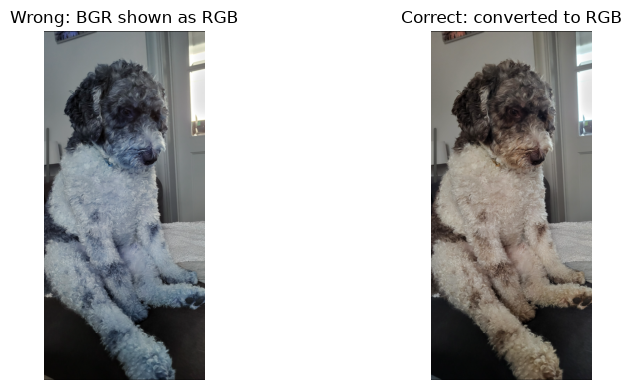

In [14]:
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(bgr)  # Deliberately incorrect display: BGR interpreted as RGB
axes[0].set_title("Wrong: BGR shown as RGB")
axes[1].imshow(rgb)
axes[1].set_title("Correct: converted to RGB")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Grayscale and individual channels

Grayscale conversion combines color information into a single intensity value. It is useful for many edge-detection and thresholding operations, but it discards chromatic information.

Inspect individual B, G, and R channels. A channel is a 2D matrix; it is not itself a full-color image. A grayscale image can be expanded to three channels, but that does **not** restore the original color information.

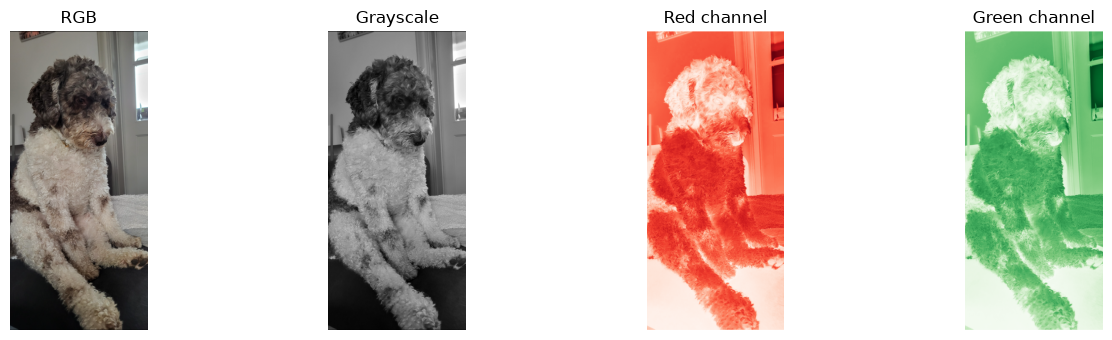

gray shape: (2556, 1179) channel shape: (2556, 1179)


In [15]:
gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
blue, green, red = cv2.split(bgr)

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
axes[0].imshow(rgb); axes[0].set_title("RGB")
axes[1].imshow(gray, cmap="gray"); axes[1].set_title("Grayscale")
axes[2].imshow(red, cmap="Reds"); axes[2].set_title("Red channel")
axes[3].imshow(green, cmap="Greens"); axes[3].set_title("Green channel")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

print("gray shape:", gray.shape, "channel shape:", red.shape)

## 6. Other color spaces: HSV, LAB, and alpha

- **HSV** separates hue (rough color), saturation, and value/brightness. It can make color-based segmentation easier under some conditions, but hue becomes unstable for very low-saturation pixels.
- **CIELAB / LAB** separates a lightness-like channel from two color-opponent channels. It can be useful for perceptual color comparisons.
- **Alpha** is a transparency channel in some PNG/TIFF images. Standard `cv2.imread(..., IMREAD_COLOR)` discards alpha; use `IMREAD_UNCHANGED` when it matters.

Color spaces are representations, not magic fixes for lighting variation. Test on the full range of conditions expected in production.

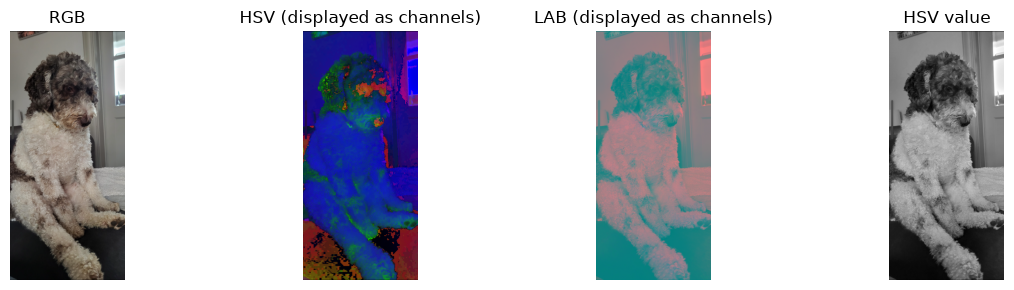

IMREAD_UNCHANGED shape: (2556, 1179, 3) | dtype: uint8


In [16]:
hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB)

fig, axes = plt.subplots(1, 4, figsize=(13, 3))
axes[0].imshow(rgb); axes[0].set_title("RGB")
axes[1].imshow(hsv); axes[1].set_title("HSV (displayed as channels)")
axes[2].imshow(lab); axes[2].set_title("LAB (displayed as channels)")
axes[3].imshow(hsv[:, :, 2], cmap="gray"); axes[3].set_title("HSV value")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

# Read unchanged to inspect whether the file has an alpha channel.
if IMAGE_PATH and Path(IMAGE_PATH).is_file():
    unchanged = cv2.imread(IMAGE_PATH, cv2.IMREAD_UNCHANGED)
    print("IMREAD_UNCHANGED shape:", None if unchanged is None else unchanged.shape,
          "| dtype:", None if unchanged is None else unchanged.dtype)
else:
    print("Synthetic sample has no alpha channel.")

## 7. Histograms, contrast, and pixel statistics

A histogram shows how often intensity values occur. It can reveal underexposure, overexposure, or low contrast, but histogram shape alone does not tell you whether an image is good for a task.

For an 8-bit grayscale image, `calcHist` gives a count for each intensity from 0 to 255.

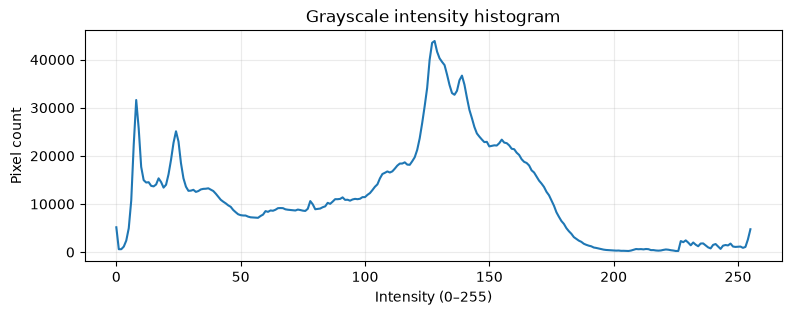

mean: 106.08 std: 53.81 min: 0 max: 255


In [17]:
hist = cv2.calcHist([gray], [0], None, [256], [0, 256]).ravel()
plt.figure(figsize=(9, 3))
plt.plot(np.arange(256), hist)
plt.title("Grayscale intensity histogram")
plt.xlabel("Intensity (0–255)")
plt.ylabel("Pixel count")
plt.grid(True, alpha=0.25)
plt.show()

print("mean:", round(float(gray.mean()), 2),
      "std:", round(float(gray.std()), 2),
      "min:", int(gray.min()), "max:", int(gray.max()))

## 8. Resize, crop, normalize, and standardize

These operations are common when preparing model inputs:

- **Resize:** standardizes dimensions. `INTER_AREA` is often good for shrinking; `INTER_LINEAR` is a common general-purpose choice; `INTER_CUBIC` can be useful for enlarging.
- **Crop:** selects a region. Be careful not to crop out the object or label-relevant context.
- **Scale to [0, 1]:** converts `uint8` values to floating-point values from 0 to 1.
- **Standardize:** subtract a mean and divide by a standard deviation, often per channel. Use statistics computed from the **training split only**, then apply those same values to validation/test data.

Forcing every image into a fixed width and height can distort objects. Consider aspect-ratio-preserving resize plus padding when geometry matters.

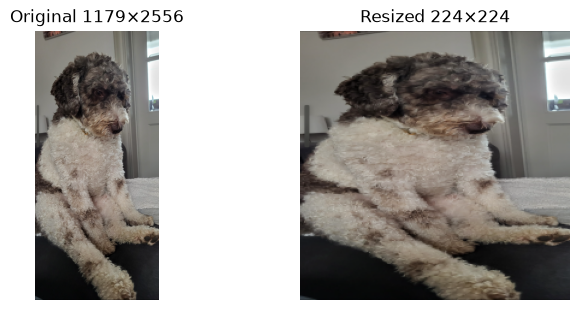

float range: 0.0 1.0 dtype: float32


In [18]:
target_size = (224, 224)  # OpenCV order is (width, height)
resized_bgr = cv2.resize(bgr, target_size, interpolation=cv2.INTER_AREA)
resized_rgb = cv2.cvtColor(resized_bgr, cv2.COLOR_BGR2RGB)
float01 = resized_rgb.astype(np.float32) / 255.0

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
axes[0].imshow(rgb); axes[0].set_title(f"Original {width}×{height}")
axes[1].imshow(resized_rgb); axes[1].set_title("Resized 224×224")
for ax in axes: ax.axis("off")
plt.show()
print("float range:", float(float01.min()), float(float01.max()), "dtype:", float01.dtype)

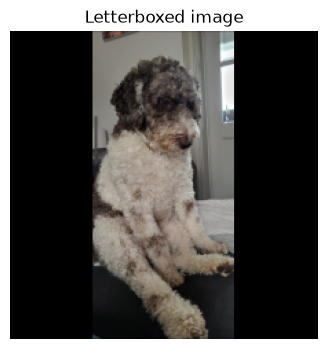

scale, x_offset, y_offset, new_width, new_height: (0.08763693270735524, 60, 0, 103, 224)


In [19]:
# Aspect-ratio-preserving resize with padding (letterboxing).
def letterbox(image, target_width=224, target_height=224, fill=0):
    h, w = image.shape[:2]
    scale = min(target_width / w, target_height / h)
    nw, nh = max(1, round(w * scale)), max(1, round(h * scale))
    interp = cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR
    resized = cv2.resize(image, (nw, nh), interpolation=interp)
    if image.ndim == 2:
        canvas = np.full((target_height, target_width), fill, dtype=image.dtype)
    else:
        canvas = np.full((target_height, target_width, image.shape[2]), fill, dtype=image.dtype)
    x0, y0 = (target_width - nw) // 2, (target_height - nh) // 2
    canvas[y0:y0+nh, x0:x0+nw] = resized
    return canvas, (scale, x0, y0, nw, nh)

boxed, letterbox_info = letterbox(bgr)
plt.figure(figsize=(4,4))
plt.imshow(cv2.cvtColor(boxed, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.title("Letterboxed image")
plt.show()
print("scale, x_offset, y_offset, new_width, new_height:", letterbox_info)

## 9. Denoising and sharpening

Filters can suppress noise or emphasize detail, but they also change the data distribution. Compare the result to the original and decide whether the transformation supports the task.

- Gaussian blur smooths high-frequency variation. It replaces each pixel with a weighted average of nearby pixels. Pixels closer to the center receive more weight than pixels farther away.

  **What it does:** Reduces small variations in brightness and color.
  
  **What is high-frequency variation?** Rapid changes between neighboring pixels, such as fine texture, tiny details, and some types of noise.
  
  **When to use it:** Before edge detection, thresholding, or other operations that are sensitive to noise.

  **Limitation:** Fine details and object boundaries can become blurry.
  
  For example, if a photo contains small random fluctuations in brightness, Gaussian blur smooths them out by averaging neighboring values.
- Median blur is often useful for salt-and-pepper noise. It replaces each pixel with the median value of the pixels in its neighborhood, rather than their average.

  Imagine these neighboring grayscale pixel values:

  20, 21, 22, 23, 255
  **The average is 68.2**, heavily affected by the extreme value 255.
  
  The median is 22, which is much closer to the ordinary neighboring values.

  This is why median filtering is particularly effective against salt-and-pepper noise (random white and black pixels scattered across an image).
  
  **What it does:** Removes isolated extreme pixels while often preserving edges better than Gaussian blur.
  
  **When to use it:** Images containing random black or white specks.
  
  **Limitation:** A large kernel can remove fine details and thin structures
- Bilateral filtering tries to smooth while preserving edges, at higher computational cost. It considers two things:

  1. Spatial distance: Nearby pixels matter more than distant pixels.

  2. Intensity or color similarity: Pixels with similar brightness or color matter more than pixels that differ significantly.
  
  For example, imagine a dark object against a bright background. A bilateral filter is less likely to average pixels across the boundary because their brightness values differ substantially.

  **What it does:** Smooths small variations within regions while trying to preserve strong edges.
  
  **When to use it:** Preprocessing photographs when object boundaries are important.
  
  **Limitation:** It is usually slower than Gaussian blur, particularly for large images or large filter neighborhoods.
- Sharpening can amplify noise and compression artifacts. Sharpening does the opposite of smoothing: it emphasizes rapid changes in brightness, making edges and fine details appear more pronounced.

  A common method uses a blurred copy of the image to estimate the smoother component, then adds the difference back to the original. This is called unsharp masking.

  **What it does:** Makes boundaries and details appear clearer.

  **When to use it:** Slightly soft images where fine detail needs to stand out.

  **Limitation:** Noise, JPEG compression artifacts, and unwanted edges can also become more visible.

  Sharpening cannot reliably recover details that were never captured in the original image.

Never overwrite the original image during experimentation.

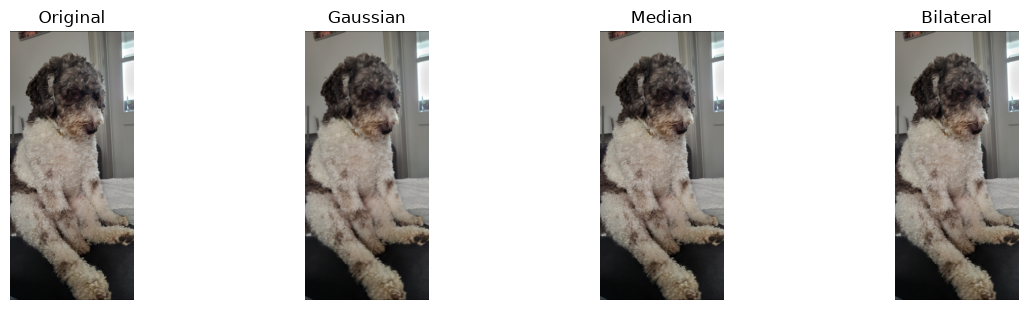

In [32]:
gaussian = cv2.GaussianBlur(bgr, (15, 15), sigmaX=0)
median = cv2.medianBlur(bgr, 5)
bilateral = cv2.bilateralFilter(bgr, d=9, sigmaColor=60, sigmaSpace=60)

fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, im, title in zip(axes, [bgr, gaussian, median, bilateral],
                         ["Original", "Gaussian", "Median", "Bilateral"]):
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

## 10. Thresholding: turning intensity into a binary mask

A binary mask labels pixels as foreground (`255`) or background (`0`). Global thresholding uses one threshold for the whole image; adaptive thresholding calculates thresholds over local neighborhoods; Otsu's method chooses a threshold from the histogram under a two-class assumption.

Thresholding works best when foreground and background are separable by intensity. It can fail with shadows, textured backgrounds, or overlapping intensity distributions.

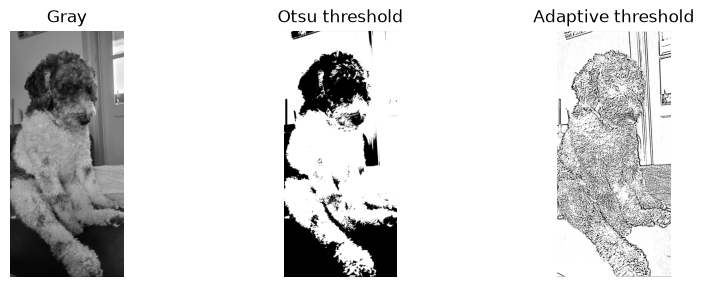

In [21]:
_, binary = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
adaptive = cv2.adaptiveThreshold(
    gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY, 31, 5
)
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
axes[0].imshow(gray, cmap="gray"); axes[0].set_title("Gray")
axes[1].imshow(binary, cmap="gray"); axes[1].set_title("Otsu threshold")
axes[2].imshow(adaptive, cmap="gray"); axes[2].set_title("Adaptive threshold")
for ax in axes: ax.axis("off")
plt.show()

## 11. Edges and borders: Sobel, Laplacian, and Canny

An **edge** is a rapid change in image intensity; it is not necessarily an object boundary. A **border** may mean the image's outer frame, an object's contour, or a region boundary. Be clear about which one you mean.

- Sobel approximates intensity derivatives in horizontal/vertical directions.
- Laplacian responds to second-order intensity changes.
- Canny combines smoothing, gradient estimation, non-maximum suppression, and hysteresis thresholding.

The thresholds are data-dependent; tune them on representative images, not just one attractive example.

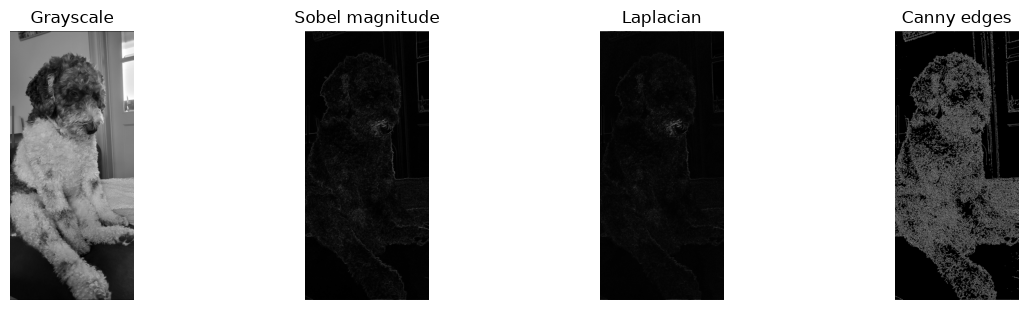

In [33]:
sobel_x = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
sobel_mag = cv2.magnitude(sobel_x, sobel_y)
sobel_vis = cv2.normalize(sobel_mag, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
lap = cv2.Laplacian(gray, cv2.CV_32F)
lap_vis = cv2.convertScaleAbs(lap)
canny = cv2.Canny(gray, 30, 60)

fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, im, title in zip(axes, [gray, sobel_vis, lap_vis, canny],
                         ["Grayscale", "Sobel magnitude", "Laplacian", "Canny edges"]):
    ax.imshow(im, cmap="gray"); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

## 12. Find contours and measure shapes

OpenCV contours trace connected boundaries in a binary image. They can provide area, perimeter, bounding rectangles, and shape approximations. Contours depend heavily on the quality of the binary mask.

- `RETR_EXTERNAL` retrieves only outer contours.
- `CHAIN_APPROX_SIMPLE` compresses redundant points.
- `contourArea` is area in pixel units, not physical units unless calibrated.

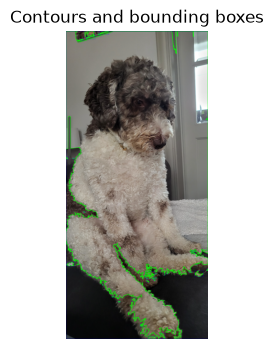

,id,area_px2,perimeter_px,x,y,width,height
388,388,2380484.5,19672.504516,0,2,1179,2552
387,387,2048.0,432.818321,151,2,86,47
221,221,1569.0,629.754395,661,1995,75,61
263,263,1199.5,220.208150,5,1916,65,35
228,228,1159.5,267.663994,1068,1989,71,50
22,22,838.5,196.953318,681,2533,66,21
385,385,411.5,304.492421,279,2,76,27
44,44,380.0,195.480229,787,2506,37,45
369,369,367.5,296.977703,167,31,75,35
137,137,349.5,147.438599,545,2214,35,30


In [23]:
contours, hierarchy = cv2.findContours(binary.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
contour_vis = bgr.copy()
records = []
for i, contour in enumerate(contours):
    area = cv2.contourArea(contour)
    perimeter = cv2.arcLength(contour, True)
    x, y, w, h = cv2.boundingRect(contour)
    records.append({"id": i, "area_px2": area, "perimeter_px": perimeter,
                    "x": x, "y": y, "width": w, "height": h})
    if area > 20:
        cv2.drawContours(contour_vis, [contour], -1, (0, 255, 0), 2)
        cv2.rectangle(contour_vis, (x, y), (x+w, y+h), (255, 0, 0), 1)

plt.figure(figsize=(7, 4))
plt.imshow(cv2.cvtColor(contour_vis, cv2.COLOR_BGR2RGB)); plt.axis("off"); plt.title("Contours and bounding boxes")
plt.show()
pd.DataFrame(records).sort_values("area_px2", ascending=False).head(10)

## 13. Morphological operations

Morphology changes binary shapes using a small structuring element (kernel):

- **Erosion:** shrinks foreground regions; may remove small noise.
- **Dilation:** expands foreground regions; may bridge small gaps.
- **Opening:** erosion followed by dilation; often removes small foreground specks.
- **Closing:** dilation followed by erosion; often fills small holes or gaps.

Kernel size and shape matter. A morphology operation can destroy thin structures or merge nearby objects.

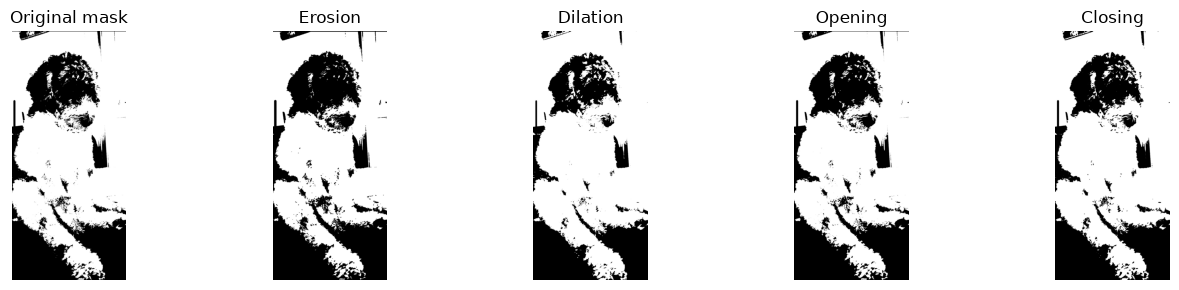

In [24]:
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
eroded = cv2.erode(binary, kernel, iterations=1)
dilated = cv2.dilate(binary, kernel, iterations=1)
opened = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
closed = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

fig, axes = plt.subplots(1, 5, figsize=(14, 3))
for ax, im, title in zip(axes, [binary, eroded, dilated, opened, closed],
                         ["Original mask", "Erosion", "Dilation", "Opening", "Closing"]):
    ax.imshow(im, cmap="gray"); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

## 14. PCA and eigenvalues — the intuition

**Principal Component Analysis (PCA)** finds directions in data with high variance. It is often used for dimensionality reduction, exploratory analysis, compression, and feature visualization.

For a data matrix \(X\), rows are observations and columns are features:
1. Center each feature by subtracting its mean.
2. Compute the covariance matrix.
3. Find eigenvalues and eigenvectors of the covariance matrix.
4. Sort eigenvectors by descending eigenvalue.
5. Project centered data onto the top components.

An eigenvector gives a direction; its eigenvalue tells how much variance lies along that direction. Eigenvalues are not pixel intensities. For image PCA, an image can be flattened into a long feature vector, but all images must have compatible dimensions and alignment for a straightforward comparison.

In [25]:
# Tiny numerical example: observations are rows, features are columns.
X = np.array([
    [2.5, 2.4],
    [0.5, 0.7],
    [2.2, 2.9],
    [1.9, 2.2],
    [3.1, 3.0],
    [2.3, 2.7],
    [2.0, 1.6],
    [1.0, 1.1],
    [1.5, 1.6],
    [1.1, 0.9],
], dtype=np.float64)

X_centered = X - X.mean(axis=0)
cov = np.cov(X_centered, rowvar=False)
eigenvalues, eigenvectors = np.linalg.eigh(cov)  # symmetric covariance matrix
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]
explained = eigenvalues / eigenvalues.sum()

print("Covariance matrix:\n", cov)
print("Eigenvalues (descending):", eigenvalues)
print("Eigenvectors (columns):\n", eigenvectors)
print("Explained variance ratio:", explained)
projected = X_centered @ eigenvectors
print("Projected data shape:", projected.shape)

Covariance matrix:
 [[0.61655556 0.61544444]
 [0.61544444 0.71655556]]
Eigenvalues (descending): [1.28402771 0.0490834 ]
Eigenvectors (columns):
 [[ 0.6778734  -0.73517866]
 [ 0.73517866  0.6778734 ]]
Explained variance ratio: [0.96318131 0.03681869]
Projected data shape: (10, 2)


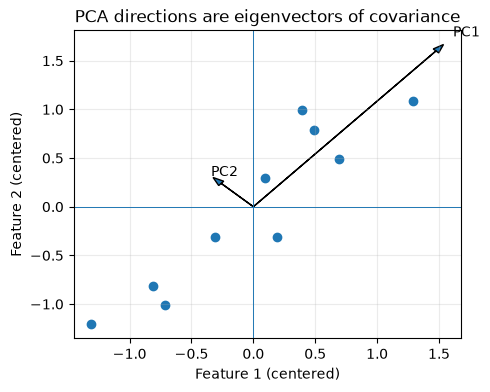

In [26]:
plt.figure(figsize=(5, 4))
plt.scatter(X_centered[:, 0], X_centered[:, 1], label="Centered observations")
origin = np.zeros(2)
for i in range(2):
    vec = eigenvectors[:, i] * np.sqrt(eigenvalues[i]) * 2
    plt.arrow(0, 0, vec[0], vec[1], head_width=0.06, length_includes_head=True)
    plt.text(vec[0]*1.05, vec[1]*1.05, f"PC{i+1}")
plt.axhline(0, linewidth=0.7); plt.axvline(0, linewidth=0.7)
plt.xlabel("Feature 1 (centered)"); plt.ylabel("Feature 2 (centered)")
plt.title("PCA directions are eigenvectors of covariance")
plt.grid(True, alpha=0.25); plt.show()

## 15. PCA on images (flattened pixels)

For an image dataset, flatten each image into a vector and stack vectors into a matrix. PCA can find common variation across the dataset, but raw-pixel PCA is sensitive to alignment, lighting, and background. This cell demonstrates the shape and calculation on one image; **one image alone is not a meaningful dataset for PCA**.

For a real dataset, use many training images with consistent preprocessing. Fit PCA on the training split only, then transform validation/test images with the fitted model.

One image as feature vector: (1, 1024) (1 sample × 1024 pixel features)
Toy dataset shape: (5, 1024)
Explained variance ratio: [0.62770355 0.2684544 ]


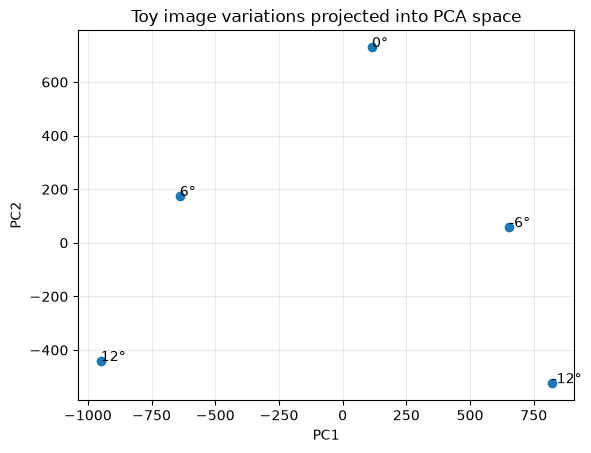

In [27]:
from sklearn.decomposition import PCA

# Example: a single image can be flattened, but cannot reveal population variation.
small_gray = cv2.resize(gray, (32, 32), interpolation=cv2.INTER_AREA)
one_vector = small_gray.astype(np.float32).reshape(1, -1)
print("One image as feature vector:", one_vector.shape, "(1 sample × 1024 pixel features)")

# Build a toy set of variations for demonstration only.
toy_images = []
for angle in [-12, -6, 0, 6, 12]:
    M = cv2.getRotationMatrix2D((16, 16), angle, 1.0)
    toy_images.append(cv2.warpAffine(small_gray, M, (32, 32)).reshape(-1))
toy_X = np.asarray(toy_images, dtype=np.float32)
pca = PCA(n_components=2)
toy_scores = pca.fit_transform(toy_X)
print("Toy dataset shape:", toy_X.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_)

plt.scatter(toy_scores[:, 0], toy_scores[:, 1])
for i, angle in enumerate([-12, -6, 0, 6, 12]):
    plt.annotate(f"{angle}°", (toy_scores[i, 0], toy_scores[i, 1]))
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("Toy image variations projected into PCA space")
plt.grid(True, alpha=0.25); plt.show()

## 16. Segmentation: what is being predicted?

Segmentation assigns a label to each pixel. It differs from classification (one label for an image) and object detection (boxes around objects).

Common types:
- **Binary segmentation:** foreground versus background.
- **Semantic segmentation:** each pixel gets a class, such as road, person, or sky.
- **Instance segmentation:** separate object instances are identified even when they share a class.

A training example often consists of an image and a pixel mask. The mask must be aligned with the image. For categorical masks, use nearest-neighbor resizing; linear interpolation creates invalid blended class IDs.

## 17. Segmentation method A — color thresholding in HSV

This is a simple, interpretable baseline for objects with a distinct color. The thresholds below are only an example; adjust them for your images. OpenCV's HSV hue range for 8-bit images is 0–179, not 0–360.

For red, hue wraps around the end of the hue range, so two intervals are often combined. The sample below targets green-ish pixels in the synthetic example.

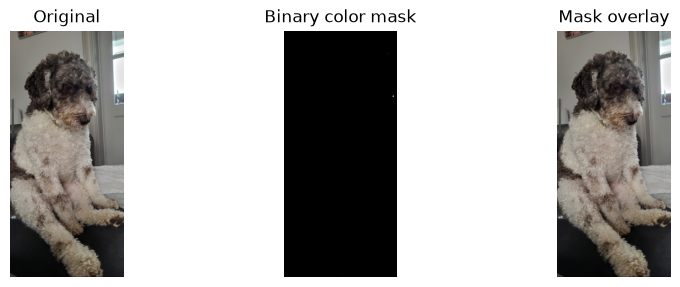

In [28]:
hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
lower = np.array([35, 50, 40], dtype=np.uint8)
upper = np.array([90, 255, 255], dtype=np.uint8)
color_mask = cv2.inRange(hsv, lower, upper)

overlay = bgr.copy()
overlay[color_mask > 0] = (0, 0, 255)  # mark selected pixels in red (BGR)
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
axes[0].imshow(rgb); axes[0].set_title("Original")
axes[1].imshow(color_mask, cmap="gray"); axes[1].set_title("Binary color mask")
axes[2].imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB)); axes[2].set_title("Mask overlay")
for ax in axes: ax.axis("off")
plt.show()

## 18. Segmentation method B — k-means clustering

K-means groups pixels into \(k\) clusters by color (or by color plus spatial coordinates). It is unsupervised: clusters do not automatically correspond to meaningful semantic classes. Cluster IDs can change between runs, and the result depends on `k`, initialization, and image content.

This demonstration clusters RGB colors. For large images, clustering every pixel may be slow; sample pixels or downsample first.

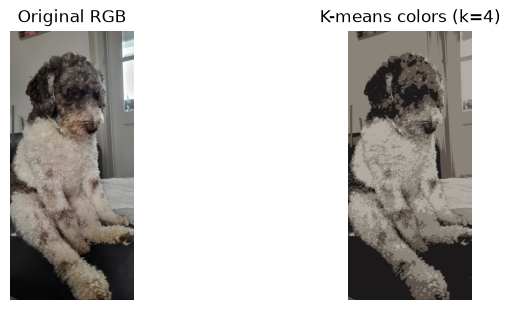

Cluster centers (RGB):
 [[ 92  82  74]
 [137 131 122]
 [ 27  25  25]
 [178 172 164]]


In [29]:
Z = rgb.reshape((-1, 3)).astype(np.float32)
k = 4
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 1.0)
compactness, labels, centers = cv2.kmeans(
    Z, k, None, criteria, 5, cv2.KMEANS_PP_CENTERS
)
centers_u8 = np.uint8(centers)
clustered_rgb = centers_u8[labels.flatten()].reshape(rgb.shape)

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))
axes[0].imshow(rgb); axes[0].set_title("Original RGB")
axes[1].imshow(clustered_rgb); axes[1].set_title(f"K-means colors (k={k})")
for ax in axes: ax.axis("off")
plt.show()
print("Cluster centers (RGB):\n", centers_u8)

## 19. Segmentation method C — watershed

Watershed is a classical approach for separating touching objects. It usually requires a good foreground/background estimate and can be sensitive to noise. The common workflow uses thresholding, morphology, distance transform, and markers.

This cell demonstrates the mechanics. Results on real imagery may need parameter tuning or a different segmentation approach.

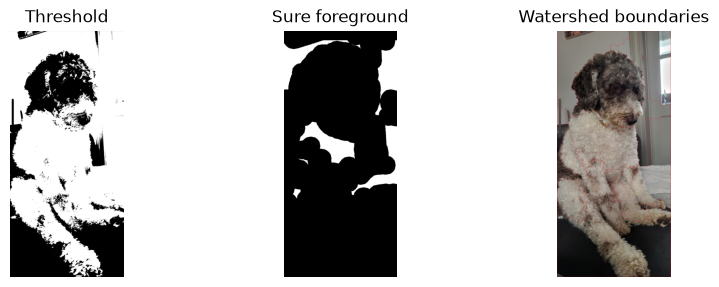

In [30]:
# Start from a binary image and build markers.
bw = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1]
kernel = np.ones((3, 3), np.uint8)
opening = cv2.morphologyEx(bw, cv2.MORPH_OPEN, kernel, iterations=2)
sure_bg = cv2.dilate(opening, kernel, iterations=3)
dist = cv2.distanceTransform(opening, cv2.DIST_L2, 5)
_, sure_fg = cv2.threshold(dist, 0.35 * dist.max(), 255, 0)
sure_fg = np.uint8(sure_fg)
unknown = cv2.subtract(sure_bg, sure_fg)
n_markers, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown == 255] = 0

watershed_img = bgr.copy()
markers_ws = cv2.watershed(watershed_img, markers.copy())
watershed_img[markers_ws == -1] = (0, 0, 255)  # boundaries in red

fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
axes[0].imshow(bw, cmap="gray"); axes[0].set_title("Threshold")
axes[1].imshow(sure_fg, cmap="gray"); axes[1].set_title("Sure foreground")
axes[2].imshow(cv2.cvtColor(watershed_img, cv2.COLOR_BGR2RGB)); axes[2].set_title("Watershed boundaries")
for ax in axes: ax.axis("off")
plt.show()

## 20. Segmentation masks for model training

A mask is often stored as a single-channel image where each pixel holds a class ID:
- Binary task: often 0 = background, 1 = foreground (or 0/255 in image files).
- Multi-class task: 0, 1, 2, ... represent classes.
- Do not assume `255` means foreground in every dataset; check the dataset's specification.

**Image and mask must stay geometrically aligned.** Apply the same crop, flip, rotation, and resize parameters to both. Use nearest-neighbor interpolation for categorical masks. Image augmentation and mask augmentation must be synchronized.

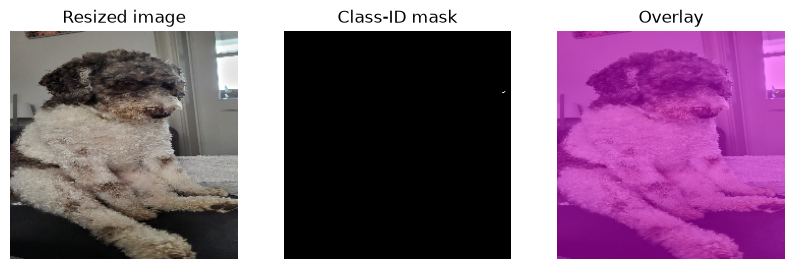

In [31]:
# Demonstrate nearest-neighbor resizing for a categorical mask.
# Convert the 0/255 mask to class IDs 0/1 for a typical segmentation target.
mask_class_ids = (color_mask > 0).astype(np.uint8)
mask_resized = cv2.resize(mask_class_ids, (224, 224), interpolation=cv2.INTER_NEAREST)
image_resized = cv2.resize(rgb, (224, 224), interpolation=cv2.INTER_LINEAR)

assert set(np.unique(mask_resized)).issubset({0, 1})
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
axes[0].imshow(image_resized); axes[0].set_title("Resized image")
axes[1].imshow(mask_resized, cmap="gray", vmin=0, vmax=1); axes[1].set_title("Class-ID mask")
axes[2].imshow(image_resized); axes[2].imshow(mask_resized, cmap="spring", alpha=0.45, vmin=0, vmax=1)
axes[2].set_title("Overlay")
for ax in axes: ax.axis("off")
plt.show()

In [ ]:
# For a local Jupyter Notebook:
image_path = "/content/IMG-20190301-WA0000.jpg"

# OpenCV loads images in BGR format
image_bgr = cv2.imread(image_path)

if image_bgr is None:
    raise FileNotFoundError(
        f"Could not load {image_path}. Check the file path."
    )

# Convert BGR to RGB for correct display with Matplotlib
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 6))
plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")
plt.show()

In [ ]:
# Convert to grayscale
gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)

# Apply Otsu's automatic thresholding
threshold_value, mask = cv2.threshold(
    gray,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Create a color image showing only the foreground
segmented = cv2.bitwise_and(
    image_rgb,
    image_rgb,
    mask=mask
)

# Overlay the mask on the original image
overlay = image_rgb.copy()
overlay[mask > 0] = (
    0.5 * image_rgb[mask > 0] +
    0.5 * np.array([255, 0, 0])
).astype(np.uint8)

# Display results
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(image_rgb)
axes[0].set_title("Original")

axes[1].imshow(gray, cmap="gray")
axes[1].set_title("Grayscale")

axes[2].imshow(mask, cmap="gray")
axes[2].set_title(f"Binary Mask (T={threshold_value:.0f})")

axes[3].imshow(overlay)
axes[3].set_title("Foreground Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Reshape the image so each pixel is one RGB data point
pixels = image_rgb.reshape((-1, 3)).astype(np.float32)

# Number of color clusters
K = 3

# K-means stopping criteria
criteria = (
    cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER,
    100,
    0.2
)

# Run K-means clustering
compactness, labels, centers = cv2.kmeans(
    pixels,
    K,
    None,
    criteria,
    10,  # Number of random initializations
    cv2.KMEANS_PP_CENTERS
)

# Reconstruct the image using each pixel's cluster center
centers = np.uint8(centers)
segmented_kmeans = centers[labels.flatten()]
segmented_kmeans = segmented_kmeans.reshape(image_rgb.shape)

# Create a colorful label map for visualizing the clusters
label_map = labels.reshape(image_rgb.shape[:2])

plt.figure(figsize=(7, 5))
plt.imshow(label_map, cmap="tab10", vmin=0, vmax=K-1)
plt.title(f"K-means Segmentation Labels (K={K})")
plt.axis("off")
plt.show()

# Compare original and segmented images
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].imshow(image_rgb)
axes[0].set_title("Original Image")

axes[1].imshow(segmented_kmeans)
axes[1].set_title(f"Color Segmentation (K={K})")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 21. Read a video and inspect its frames with OpenCV

A video is a sequence of frames plus timing information. `VideoCapture` can read from a file or, depending on environment and permissions, a camera index such as `0`.

Important checks:
- Confirm `cap.isOpened()`.
- Check whether each `read()` succeeded.
- Video metadata such as FPS and frame count can be missing or approximate.
- `CAP_PROP_POS_MSEC` and frame seeking are backend-dependent; do not assume exact timestamps.
- Release the capture handle when finished.

In [ ]:
# Set VIDEO_PATH to a local video file to try this with your own clip.
VIDEO_PATH = "/content/video poster repair cafe.mp4"
if VIDEO_PATH and Path(VIDEO_PATH).is_file():
    cap = cv2.VideoCapture(VIDEO_PATH)
    if not cap.isOpened():
        raise RuntimeError(f"Could not open video: {VIDEO_PATH}")
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = cap.get(cv2.CAP_PROP_FRAME_COUNT)
    width_v = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height_v = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    print(f"Size={width_v}x{height_v}, FPS={fps:.2f}, reported frames={frame_count:.0f}")
    frames_rgb = []
    timestamps_ms = []
    for _ in range(25):  # read a few frames for inspection
        ok, frame_bgr = cap.read()
        if not ok:
            break
        timestamps_ms.append(cap.get(cv2.CAP_PROP_POS_MSEC))
        frames_rgb.append(cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB))
    cap.release()
    print("Frames read:", len(frames_rgb), "| timestamps (ms):", timestamps_ms)
    if frames_rgb:
        fig, axes = plt.subplots(1, len(frames_rgb), figsize=(3*len(frames_rgb), 3))
        if len(frames_rgb) == 1: axes = [axes]
        for ax, frame, t in zip(axes, frames_rgb, timestamps_ms):
            ax.imshow(frame); ax.set_title(f"{t:.0f} ms"); ax.axis("off")
        plt.show()
else:
    print("Set VIDEO_PATH to an accessible video file to run this section.")

## 22. Sample frames at a target interval

Processing every frame can be expensive and can create near-duplicate training examples. For some tasks, sampling at a target rate (for example, one frame per second) is sufficient. For action recognition or fast events, sparse sampling may miss the event.

This helper uses reported FPS as an approximation. For variable-frame-rate video, accurate timestamp sampling may require a more specialized decoder.

In [ ]:
def sample_video_frames(video_path, every_seconds=1.0, max_frames=None):
    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        raise RuntimeError(f"Could not open video: {video_path}")
    fps = cap.get(cv2.CAP_PROP_FPS)
    if not np.isfinite(fps) or fps <= 0:
        cap.release()
        raise ValueError("Video FPS unavailable; choose a decoder or sampling strategy that uses timestamps.")
    step = max(1, round(fps * every_seconds))
    sampled = []
    frame_idx = 0
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        if frame_idx % step == 0:
            sampled.append((frame_idx, frame_idx / fps, cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)))
            if max_frames is not None and len(sampled) >= max_frames:
                break
        frame_idx += 1
    cap.release()
    return sampled

# Example:
# sampled = sample_video_frames("data/clip.mp4", every_seconds=0.5, max_frames=20)
# print([(idx, round(sec, 2)) for idx, sec, _ in sampled])

## 23. Image augmentation — only transformations that preserve the label

Augmentation creates plausible variations to help models generalize. It should reflect the real-world variation expected at inference time.

Examples: small rotations, crops, flips, brightness changes, or mild blur. But:
- A horizontal flip may change meaning for text, medical orientation, road signs, or asymmetric objects.
- Large rotations may create impossible examples.
- For segmentation, transform masks with the same geometry as images and use nearest-neighbor interpolation for masks.
- Apply augmentation to the **training set only**, not validation/test.

In [ ]:
# A simple visual augmentation example (not applied to the dataset automatically).
aug_flip = cv2.flip(bgr, 1)
aug_bright = cv2.convertScaleAbs(bgr, alpha=1.0, beta=25)  # add brightness offset
aug_rotate_matrix = cv2.getRotationMatrix2D((width/2, height/2), 8, 1.0)
aug_rotate = cv2.warpAffine(bgr, aug_rotate_matrix, (width, height))

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, im, title in zip(axes, [bgr, aug_flip, aug_bright, aug_rotate],
                         ["Original", "Horizontal flip", "Brighter", "Rotate 8°"]):
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()

## 24. Dataset hygiene: splits, leakage, labels, and reproducibility

A preprocessing pipeline can be technically correct and still produce misleading evaluation if the dataset is split incorrectly.

**Recommended order**
1. Audit files, labels, dimensions, corrupt files, and duplicates.
2. Split data into train/validation/test at the right unit (often subject, patient, site, camera, or original video—not individual frames).
3. Fit data-dependent transforms on training data only (means/stds, PCA, learned normalization, feature selection).
4. Apply the fitted transform to validation/test without refitting.
5. Use augmentation only for training.
6. Track random seeds, library versions, source dataset version, preprocessing parameters, and label definitions.

For video, randomly splitting neighboring frames between train and test causes serious leakage: almost identical frames may appear on both sides.

In [ ]:
# Simple file inventory example. Change DATA_DIR to your dataset root.
DATA_DIR = Path("data/images")
if DATA_DIR.exists():
    extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
    paths = [p for p in DATA_DIR.rglob("*") if p.suffix.lower() in extensions]
    print("Image files:", len(paths))
    inventory = []
    for p in paths:
        arr = cv2.imread(str(p), cv2.IMREAD_UNCHANGED)
        inventory.append({
            "path": str(p),
            "read_ok": arr is not None,
            "shape": None if arr is None else str(arr.shape),
            "dtype": None if arr is None else str(arr.dtype),
            "bytes": p.stat().st_size
        })
    display(pd.DataFrame(inventory).head(20))
else:
    print("No data/images folder found. Create it or set DATA_DIR to your dataset folder.")

## 25. Save processed images safely

Save processed outputs to a separate directory and preserve original data. Include deterministic names and, for real projects, a manifest recording source file, output file, operations, parameters, and software version.

OpenCV writes color images in BGR convention. If you have an RGB array, convert it back to BGR before `imwrite`.

In [ ]:
# Example export; uses the demo image and writes into a separate output folder.
OUTPUT_DIR = Path("processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
output_path = OUTPUT_DIR / "demo_resized.png"
ok = cv2.imwrite(str(output_path), resized_bgr)
print("Saved:", output_path.resolve(), "| success:", ok)

manifest_row = {
    "source": str(IMAGE_PATH) if IMAGE_PATH else "synthetic_demo",
    "output": str(output_path),
    "operation": "resize",
    "target_size_wh": target_size,
    "opencv_version": cv2.__version__
}
pd.DataFrame([manifest_row]).to_csv(OUTPUT_DIR / "manifest.csv", index=False)
print("Manifest:", (OUTPUT_DIR / "manifest.csv").resolve())

## 26. How this fits into model training and fine-tuning

Preprocessing depends on the model and its expected input contract:

- **CNN image classifier:** fixed size, correct channel order, numeric scale/normalization expected by the model, labels aligned with images.
- **Object detector:** resize/letterbox while updating bounding-box coordinates consistently.
- **Segmentation model:** image and mask transformations synchronized; masks use integer class IDs.
- **Vision transformer / pretrained model:** use the processor or preprocessing configuration shipped with the checkpoint whenever possible. It may specify resize, crop, rescale, channel order, and mean/std.
- **Fine-tuning a pretrained model:** do not invent a new normalization scheme without checking the model's documented preprocessing. Preserve the original model's expected input convention unless deliberately changing it.

Do not use test data to select thresholds, fit PCA, compute normalization statistics, tune augmentation, or choose checkpoints. That turns the test set into part of the training process.

In [ ]:


# Load image
image = cv2.imread("/content/211_ResearchThomasMore.jpg")
if image is None:
    raise FileNotFoundError("Check your image path.")

# Convert to grayscale and create a binary mask
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(gray, (5, 5), 0)
_, mask = cv2.threshold(
    blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# Detect separate objects
contours, _ = cv2.findContours(
    mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

result = image.copy()

for i, contour in enumerate(contours):
    # Ignore tiny regions (noise)
    if cv2.contourArea(contour) < 100:
        continue

    # Create a separate mask for this object
    object_mask = cv2.drawContours(
        mask.copy(), [contour], -1, 255, thickness=cv2.FILLED
    )

    # Get bounding box
    x, y, w, h = cv2.boundingRect(contour)

    # Draw box and object number
    cv2.rectangle(result, (x, y), (x+w, y+h), (0, 255, 0), 2)
    cv2.putText(result, f"Object {i+1}", (x, y-8),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)

# Display results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(mask, cmap="gray")
plt.title("Segmentation Mask")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title(f"Detected Objects: {len([c for c in contours if cv2.contourArea(c) >= 100])}")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
%pip install ultralytics matplotlib

In [ ]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
from PIL import Image

# Load a pretrained instance-segmentation model
model = YOLO("yolo26n-seg.pt")

# Path to your image
image_path = "/content/20240624_111923930_iOS.jpg"

# Predict objects and their masks
results = model.predict(image_path, conf=0.25)

# Display original image and segmentation result
result = results[0]
annotated_image = result.plot()  # Draws masks, labels and boxes

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(Image.open(image_path))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(annotated_image[:, :, ::-1])  # BGR to RGB
plt.title("YOLO Instance Segmentation")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Number of detected objects:",
      0 if result.masks is None else len(result.masks))

In [ ]:
if result.masks is not None:
    masks = result.masks.data.cpu().numpy()
    names = result.names
    classes = result.boxes.cls.cpu().numpy().astype(int)

    for i, mask in enumerate(masks):
        plt.figure(figsize=(5, 4))
        plt.imshow(mask, cmap="gray")
        plt.title(f"Object {i+1}: {names[classes[i]]}")
        plt.axis("off")
        plt.show()
else:
    print("No objects were detected.")

# Homework

1 - What are the width, height, and number of channels of your image?


(2556, 1179, 3)





2 - What does each channel represent in an RGB image?

the intensity of each color so intensety of RED , GREEN and BLUE

3 - What happens if you display the image using BGR values as if they were RGB?

The Red and Green seems switched

4 - What is the numerical range of the pixel values? What would change if you normalized them to \([0,1]\)?

the range standard is 0 to 255 if you normalise it would be 1 the strongest intensity of that channel and 0 no intensity of that channel

Try out some filters:

1 - Which filter produces the smoothest image?

the bilateral sharpening looks like the smoothest image



2 - Which filter seems to preserve object boundaries best?

The canny edges works pritty good it seems like , but for general shape detection 

3 - Increase the Gaussian kernel from \(5\times5\) to \(15\times15\). What changes?

could not really see a difference

4 - Does sharpening improve the image? Can you see any noise or unwanted artifacts becoming more visible?

it makes everything stand out more in an image , this will probably show small unwanted backround noise more visable.

5 - If your image contains salt-and-pepper noise, which filter would you choose, and why?

the median filter because it takes the 0 or 255 and replaces it with the median of the surounding pixels


Use Canny edge detection on your image.

1 - Which objects or structures are outlined in the result?

my dog is clearly visable and the background less but it also outlines some hars on the dog itselve

2 - Change the thresholds from (100, 200) to (30, 80). Are more or fewer edges detected?

there is way more edge detection

3 - Why might texture inside an object create edges that are not object boundaries?

because of color differences or shades that are detected as a diff number lower or higher meaning a possible edge

4  -What happens if you apply Gaussian blur before Canny? Does it remove useful edges as well as noise?

you would have to find a good balance and i thin that the edge detection would work better.

Upload some pictures of your face and check the mean of it and delete it from the pictures (Use PCA to represent the rows with fewer components.)


1 - What does an eigenvalue represent in this PCA analysis?

the value represents the difference between the variance of the images

2 - Are the first few eigenvalues much larger than the others? What does this suggest about the image's variation?

YES , that the image has a few like features / differences and than the rest is redundant

3 - What information might be lost when using fewer components?

the smaller details of the image 


Use a pretrained YOLO segmentation model to detect objects and generate pixel masks.


1 - How many individual objects does the model detect?

    1 object being a person

2 - Does each mask follow the object's outline accurately?

    yes it mostly follows my outline

3 - Does the model miss any objects or include background pixels?

    not really its a blank background , it maybe could of detected headphones but they are an accessory on a person

4 - Change the confidence threshold from 0.25 to 0.5. How does the result change?

    does't seem to change much

5 - How is model-based segmentation different from simple thresholding?

    tresholding works with pixels so it selects like rules and than based on those rules it will detect objects those rule scan be brightness or something.

    model based is training a nn and based on that nn it will detect objects

6 - Would the model work equally well on medical images, satellite images, or microscopic images? Explain.

    with some research it said no , becuase yolo is trained on everyday pictures like animals or people but not on satalite or medical images , ofcourse if a model like yolo would be trained on those images it could work.

Prepare an image for an AI model
Choose one task:
- Detect edges in an image.                     THIS ONE
- Separate an object from its background.
- Reduce noise while preserving important details.
- Compress the image representation using PCA.
Your task: Build a preprocessing pipeline with at least two operations and compare the original image with the final result.

Answer these questions:
1. What is the goal of your pipeline?
    Goal is to find the dges
2. Which operations did you choose, and in what order?
    Grayscale into a gaussian blur into canny edge detection
3. Why did you choose those operations?
    canny uses 1 color channel and blur removes the noise
4. What improved, and what became worse?
    the blur removes noise but makes smaller detailed edges not detectable
5. How could your preprocessing choices affect a machine learning model's predictions?
    it could make it not detect enough or keep to much noise , wich both is bad data and the model will than not be optimized
6. How would you measure whether your preprocessing was successful?
    for edge detection just look at some images you did the preprocessing for and than test with and without the preprocessed images is a common test.

Data matrix: (30, 4096) (images x pixels)
First 10 eigenvalues: [1.6591996e+06 8.4915150e+05 3.8388991e+05 3.1172259e+05 1.4016059e+05
 1.3168520e+05 5.7778500e+04 4.7464898e+04 3.9941801e+04 2.9736699e+04]
 1 components keep 43.5% of the variance
 3 components keep 75.9% of the variance
 5 components keep 87.8% of the variance
10 components keep 95.8% of the variance


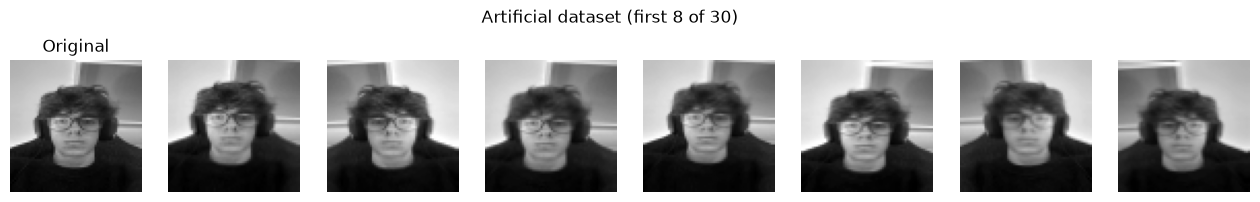

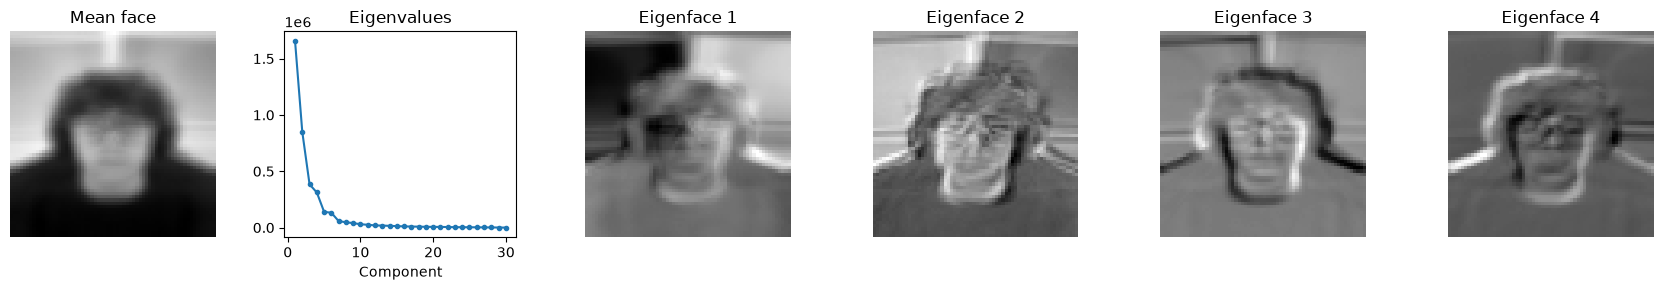

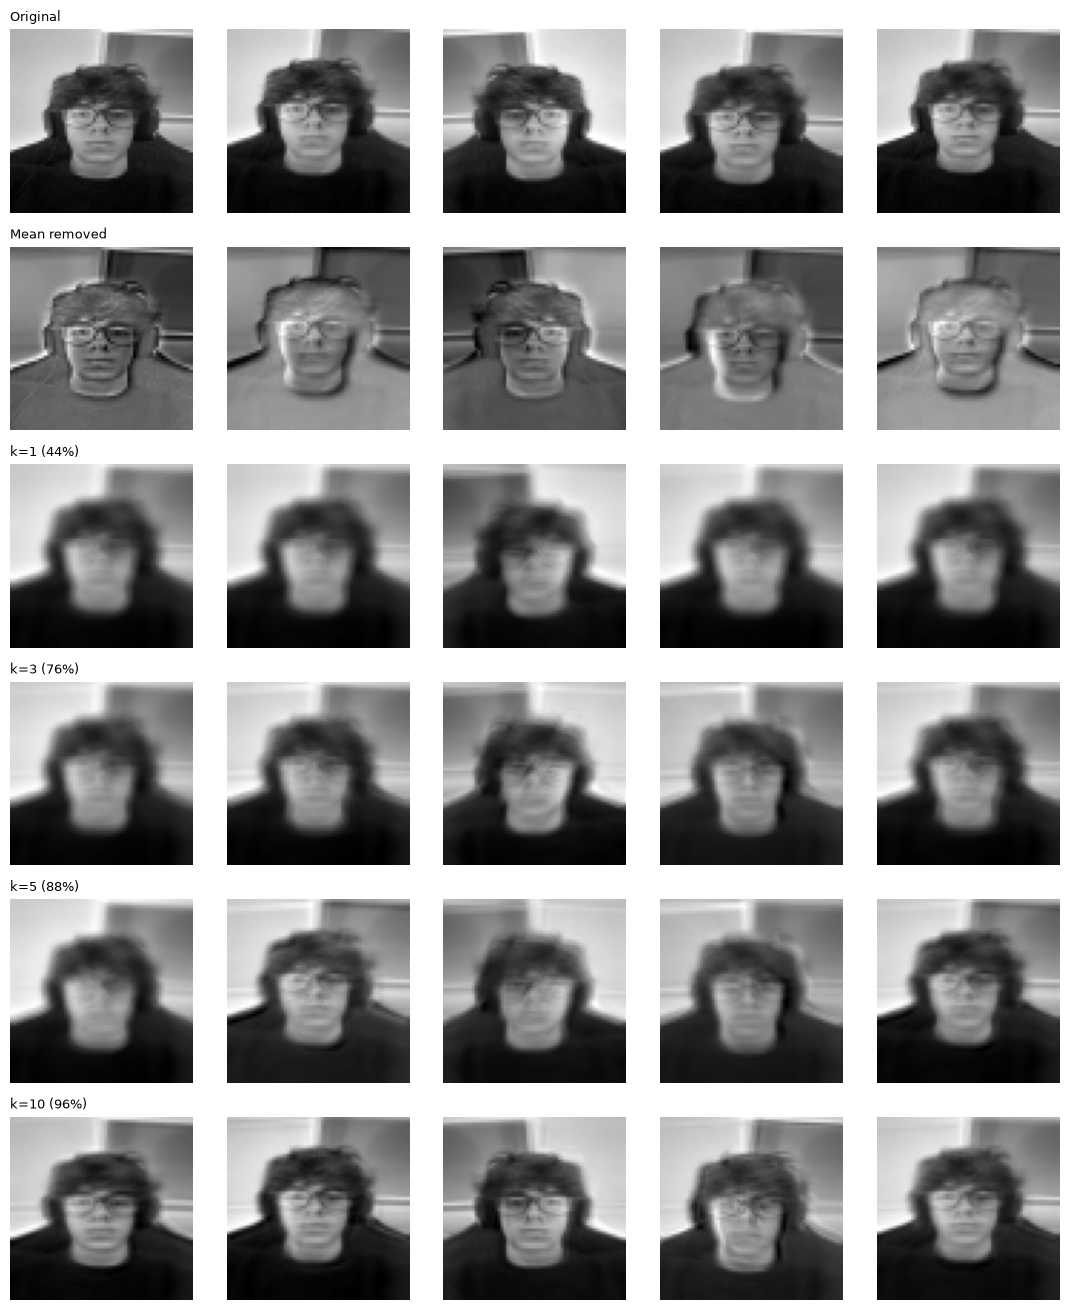

In [37]:
from sklearn.decomposition import PCA

# 1. Load ONE face photo
FACE_PATH = r"C:\Users\nolan\OneDrive\Desktop\AIFrameworksTasks\lec5\data\images\IMG_7887.jpg"  # change to your file
SIZE = 64
face = cv2.imread(FACE_PATH, cv2.IMREAD_GRAYSCALE)
if face is None:
    raise FileNotFoundError(f"Could not load {FACE_PATH}")
face = cv2.resize(face, (SIZE, SIZE), interpolation=cv2.INTER_AREA)

# 2. Create artificial variations (augmentation)
rng = np.random.default_rng(0)
def augment(img):
    scale = rng.uniform(0.95, 1.05)               # slight zoom
    tx, ty = rng.uniform(-2, 2, size=2)           # small shift
    M = np.float32([[scale, 0, (1 - scale) * SIZE / 2 + tx],
                    [0, scale, (1 - scale) * SIZE / 2 + ty]])
    out = cv2.warpAffine(img, M, (SIZE, SIZE), borderMode=cv2.BORDER_REFLECT)
    out = cv2.convertScaleAbs(out, alpha=rng.uniform(0.8, 1.2), beta=rng.uniform(-25, 25))  # contrast/brightness
    if rng.random() < 0.5:
        out = cv2.flip(out, 1)                    # mirror
    return out


faces = [face] + [augment(face) for _ in range(29)]
X = np.array([f.reshape(-1) for f in faces], dtype=np.float32)  # rows = images, columns = pixels
print("Data matrix:", X.shape, "(images x pixels)")

# 3. Mean face, and subtract it from every picture
mean_face = X.mean(axis=0)
X_centered = X - mean_face

# 4. PCA
pca = PCA().fit(X_centered)
eigenvalues = pca.explained_variance_
cumulative = np.cumsum(pca.explained_variance_ratio_)
print("First 10 eigenvalues:", np.round(eigenvalues[:10], 1))
for k in (1, 3, 5, 10):
    print(f"{k:>2} components keep {cumulative[k-1]*100:.1f}% of the variance")

# 5. Some of the augmented faces
fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
for ax, f in zip(axes, faces):
    ax.imshow(f, cmap="gray"); ax.axis("off")
axes[0].set_title("Original"); plt.suptitle("Artificial dataset (first 8 of 30)"); plt.show()

# 6. Mean face, eigenvalues, and the top "eigenfaces"
fig, axes = plt.subplots(1, 6, figsize=(17, 3))
axes[0].imshow(mean_face.reshape(SIZE, SIZE), cmap="gray"); axes[0].set_title("Mean face"); axes[0].axis("off")
axes[1].plot(np.arange(1, len(eigenvalues) + 1), eigenvalues, "o-", markersize=3)
axes[1].set_xlabel("Component"); axes[1].set_title("Eigenvalues")
for i, ax in enumerate(axes[2:]):
    ax.imshow(pca.components_[i].reshape(SIZE, SIZE), cmap="gray")
    ax.set_title(f"Eigenface {i+1}"); ax.axis("off")
plt.tight_layout(); plt.show()

# 7. Mean removed, and rebuilt from fewer components
ks = [1, 3, 5, 10]
show = 5
fig, axes = plt.subplots(2 + len(ks), show, figsize=(2.2 * show, 2.2 * (2 + len(ks))))
rows = [("Original", X), ("Mean removed", X_centered)]
for k in ks:
    p = PCA(n_components=k).fit(X_centered)
    rows.append((f"k={k} ({cumulative[k-1]*100:.0f}%)", p.inverse_transform(p.transform(X_centered)) + mean_face))
for r, (label, data) in enumerate(rows):
    for i in range(show):
        axes[r, i].imshow(data[i].reshape(SIZE, SIZE), cmap="gray"); axes[r, i].axis("off")
    axes[r, 0].set_title(label, loc="left", fontsize=9)
plt.tight_layout(); plt.show()


Creating new Ultralytics Settings v0.0.8 file  
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\nolan\AppData\Roaming\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings

=== conf=0.25: 1 objects detected ===
  person          confidence 0.92


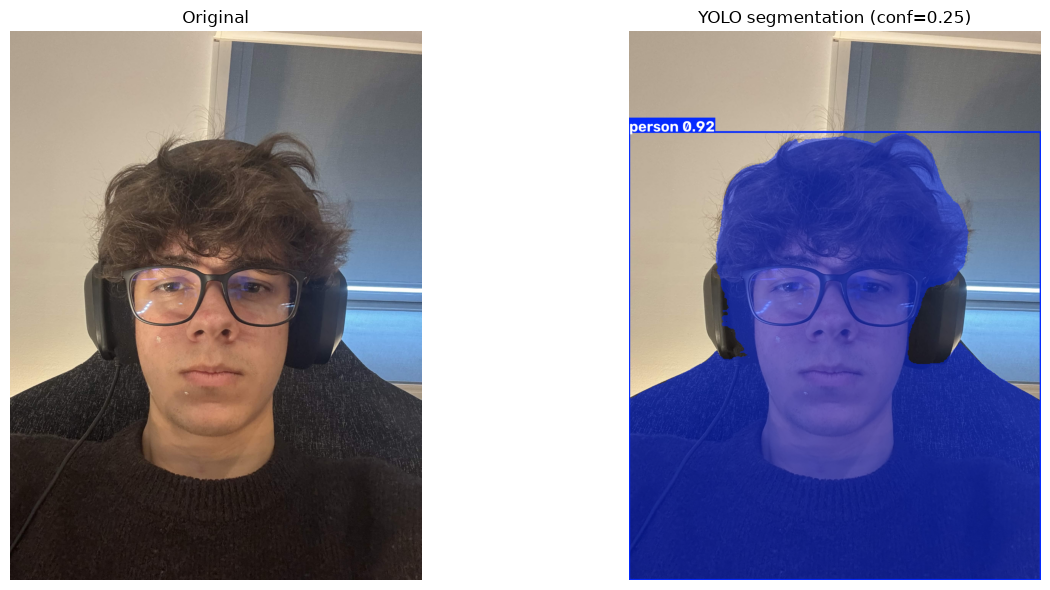


=== conf=0.5: 1 objects detected ===
  person          confidence 0.92


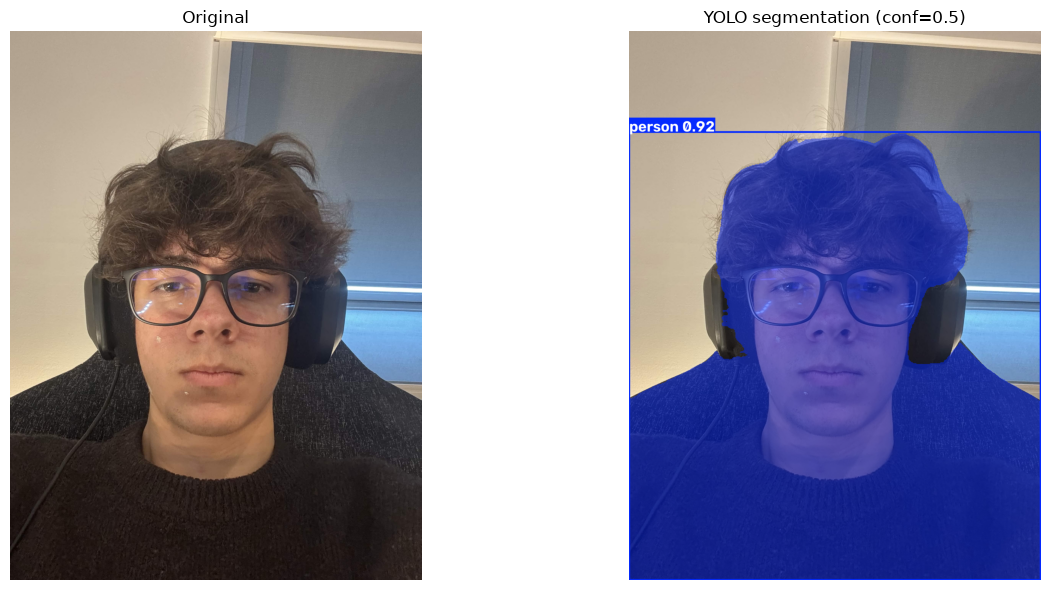

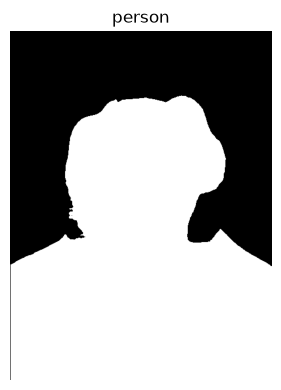

In [38]:
# If ultralytics isn't installed yet, run this once, then restart the kernel:
# %pip install ultralytics

from ultralytics import YOLO

# 1. Load a pretrained segmentation model (downloads automatically the first time)
model = YOLO("yolo26n-seg.pt")

# 2. Your image
image_path = r"C:\Users\nolan\OneDrive\Desktop\AIFrameworksTasks\lec5\data\images\IMG_7887.jpg"

# 3. Run the model at two confidence thresholds (question 4)
for conf in (0.25, 0.5):
    result = model.predict(image_path, conf=conf, verbose=False)[0]
    n = 0 if result.masks is None else len(result.masks)
    print(f"\n=== conf={conf}: {n} objects detected ===")
    for cls, score in zip(result.boxes.cls.cpu().numpy().astype(int), result.boxes.conf.cpu().numpy()):
        print(f"  {result.names[cls]:<15} confidence {score:.2f}")

    # Original vs. annotated result
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    axes[0].imshow(cv2.cvtColor(cv2.imread(image_path), cv2.COLOR_BGR2RGB)); axes[0].set_title("Original")
    axes[1].imshow(result.plot()[:, :, ::-1]); axes[1].set_title(f"YOLO segmentation (conf={conf})")
    for ax in axes: ax.axis("off")
    plt.tight_layout(); plt.show()

# 4. Show each pixel mask separately (at conf=0.25)
result = model.predict(image_path, conf=0.25, verbose=False)[0]
if result.masks is not None:
    masks = result.masks.data.cpu().numpy()
    classes = result.boxes.cls.cpu().numpy().astype(int)
    fig, axes = plt.subplots(1, len(masks), figsize=(4 * len(masks), 4), squeeze=False)
    for ax, mask, cls in zip(axes[0], masks, classes):
        ax.imshow(mask, cmap="gray"); ax.set_title(result.names[cls]); ax.axis("off")
    plt.tight_layout(); plt.show()
else:
    print("No objects were detected.")


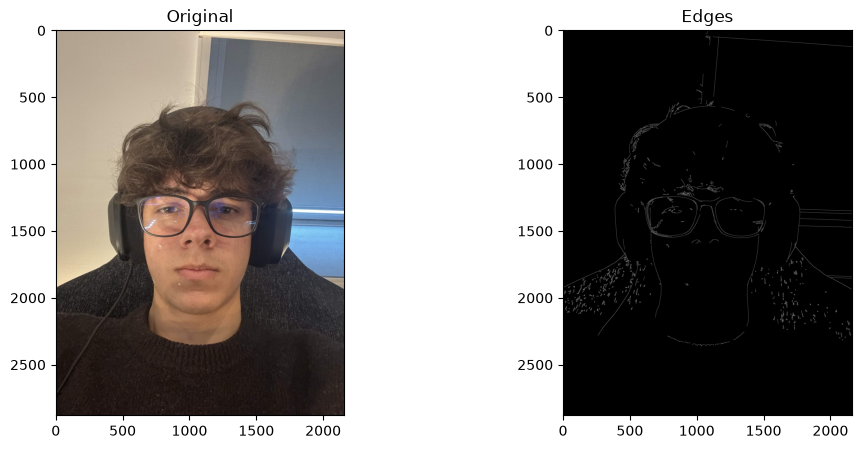

: 

In [ ]:
image = cv2.imread("C:\\Users\\nolan\\OneDrive\\Desktop\\AIFrameworksTasks\\lec5\\data\\images\\IMG_7887.jpg")

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)   
blur = cv2.GaussianBlur(gray, (5, 5), 0)         
edges = cv2.Canny(blur, 50, 150)                 

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB)); axes[0].set_title("Original")
axes[1].imshow(edges, cmap="gray"); axes[1].set_title("Edges")
plt.show()
